
# EDA: 2022 Market Stress

**Owner:** Fatima Nasir · Week 1 · RGBFS Project

## Goal
Explore the S&P 500 market during the 2022 stress period using historical price data. Examine market performance, drawdowns, realized volatility, and changes in market conditions.

## Analysis window
- Main period: 2022-01-01 to 2022-12-31
- Data source: Historical S&P 500 data
- Focus: Market overview and stress indicators


In [15]:

# Load the S&P 500 historical data
raw = pd.read_csv(ROOT / "sp500_historical_data.csv", header=0)

# The file has two metadata rows before the actual column headers.
raw = pd.read_csv(ROOT / "sp500_historical_data.csv", skiprows=2, header=None)

raw.columns = ["Date", "Close", "High", "Low", "Open", "Volume"]

# Convert columns to the correct data types
raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")

for col in ["Close", "High", "Low", "Open", "Volume"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

# Clean and sort the data
prices = (
    raw.dropna(subset=["Date", "Close"])
    .sort_values("Date")
    .reset_index(drop=True)
)

# Select the 2022 analysis period
df = prices[
    (prices["Date"] >= "2022-01-01") &
    (prices["Date"] <= "2022-12-31")
].copy()

print("Analysis period:", df["Date"].min(), "to", df["Date"].max())
print("Number of observations:", len(df))

display(df.head())


Analysis period: 2022-01-03 00:00:00 to 2022-12-26 00:00:00
Number of observations: 52


C:\Users\LATITUDE\AppData\Local\Temp\ipykernel_11132\2957802888.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")


,Date,Close,High,Low,Open,Volume
4905,2022-01-03,4677.029785,4818.620117,4662.740234,4778.140137,2.187894e+10
4906,2022-01-10,4662.850098,4748.830078,4582.240234,4655.339844,2.125184e+10
4907,2022-01-17,4397.939941,4632.240234,4395.339844,4632.240234,1.944441e+10
4908,2022-01-24,4431.850098,4453.229980,4222.620117,4356.319824,2.788909e+10
4909,2022-01-31,4500.529785,4595.310059,4414.020020,4431.790039,2.350528e+10



## 1. Data Quality Checks

Check the date coverage, missing values, and frequency of the S&P 500 observations before analyzing market stress.


In [16]:

# Check date coverage and missing values
print("Number of observations:", len(df))
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Duplicate dates:", df["Date"].duplicated().sum())
print("\nMissing values:")
print(df[["Date", "Close", "High", "Low", "Open", "Volume"]].isna().sum())

# Check observation frequency
print("\nDate gaps:")
print(df["Date"].diff().value_counts().head())


Number of observations: 52
Date range: 2022-01-03 to 2022-12-26
Duplicate dates: 0

Missing values:
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

Date gaps:
Date
7 days    51
Name: count, dtype: int64



## 2. Market Overview

Examine the S&P 500 closing price, drawdown, and rolling realized volatility during 2022. Since the available data is weekly, returns and volatility are calculated using weekly observations.


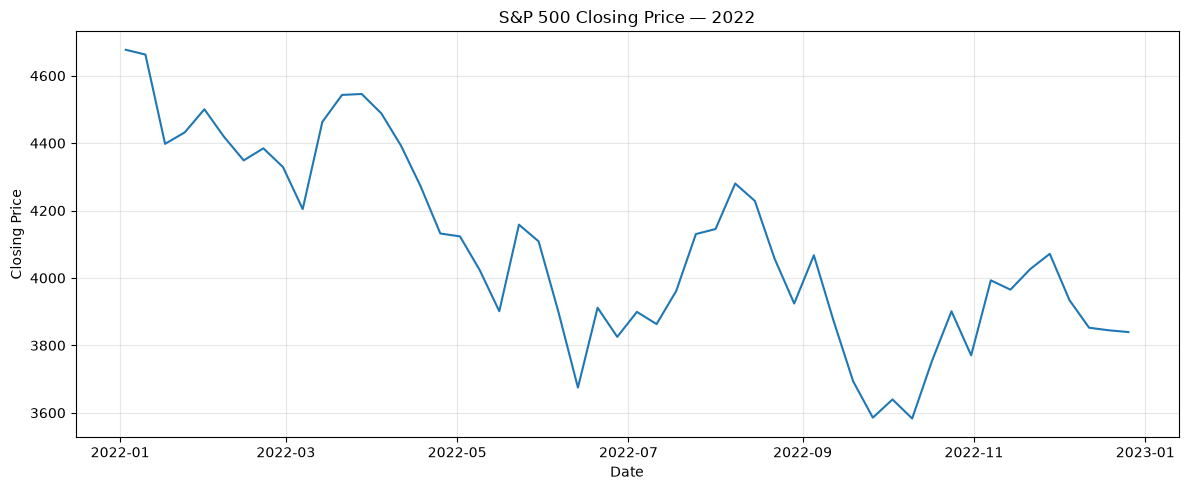

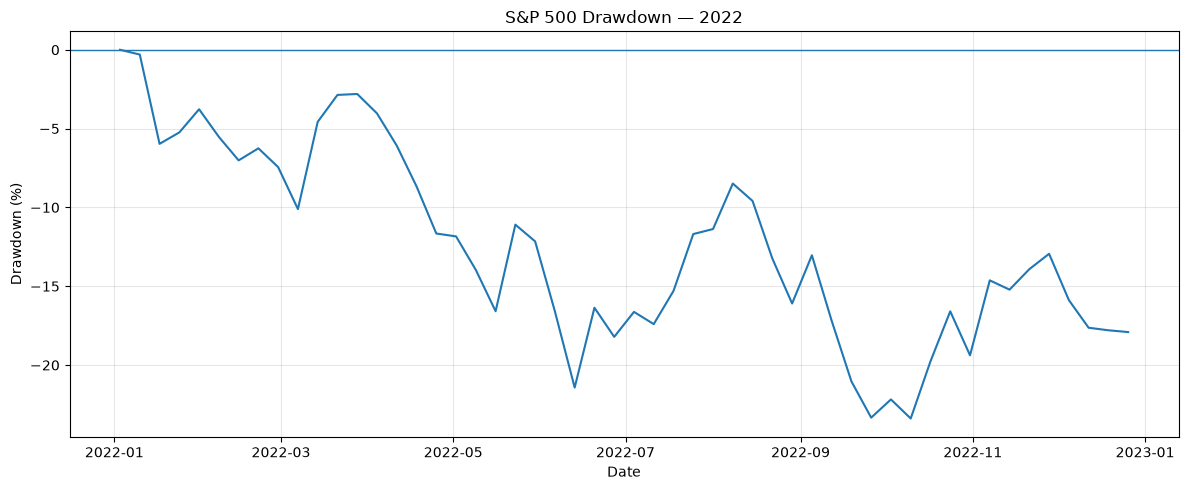

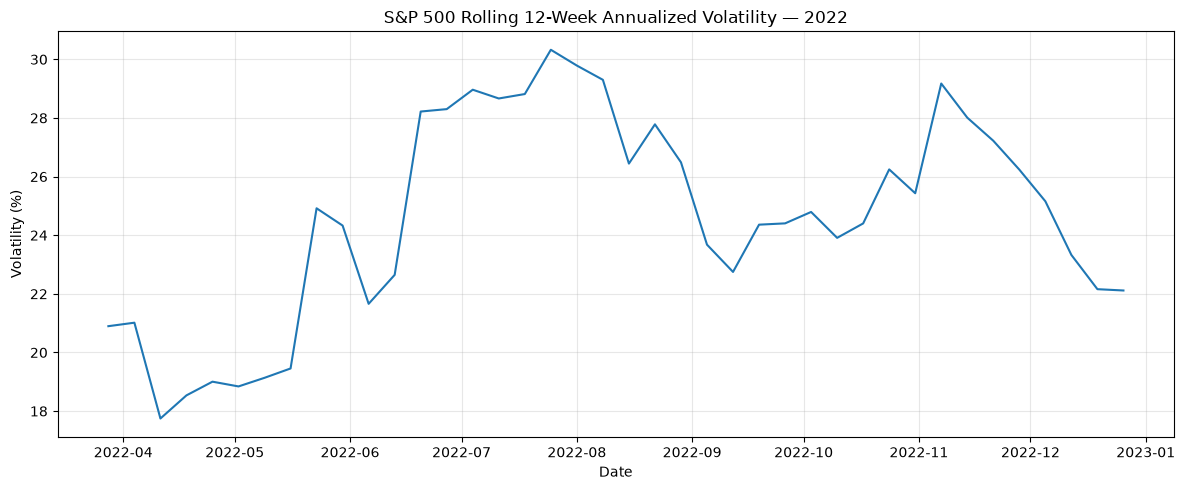

2022 total return: -17.91%
Maximum drawdown: -23.39%


In [17]:

# Calculate weekly returns and drawdown
df["Return"] = df["Close"].pct_change()

df["Running_Peak"] = df["Close"].cummax()
df["Drawdown"] = df["Close"] / df["Running_Peak"] - 1

# Estimate annualized volatility from weekly returns
df["Volatility_12w"] = (
    df["Return"].rolling(window=12).std() * np.sqrt(52)
)

# Plot S&P 500 closing price
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"])
plt.title("S&P 500 Closing Price — 2022")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot drawdown
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Drawdown"] * 100)
plt.axhline(0, linewidth=1)
plt.title("S&P 500 Drawdown — 2022")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot rolling volatility
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Volatility_12w"] * 100)
plt.title("S&P 500 Rolling 12-Week Annualized Volatility — 2022")
plt.xlabel("Date")
plt.ylabel("Volatility (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("2022 total return: {:.2f}%".format(
    (df["Close"].iloc[-1] / df["Close"].iloc[0] - 1) * 100
))
print("Maximum drawdown: {:.2f}%".format(df["Drawdown"].min() * 100))



## 3. Market Breadth and Connectedness

The reference EDA examines cross-sectional dispersion, market breadth, and connectedness using individual stock data. These analyses require a stock-level price panel rather than only the S&P 500 index.


In [18]:

# Check for the processed files used in the reference EDA
processed = ROOT / "data" / "processed"

for filename in [
    "sp500_close.parquet",
    "sp500_membership.parquet",
    "sp500_coverage_report.csv",
    "daily_panel.parquet"
]:
    print(filename, ":", (processed / filename).exists())


sp500_close.parquet : False
sp500_membership.parquet : False
sp500_coverage_report.csv : False
daily_panel.parquet : False



## 4. Market Stress Summary

Summarize the S&P 500's performance during 2022 using weekly returns, drawdown, and rolling volatility. These indicators help describe the timing and severity of market stress.


In [19]:

# Summary statistics for the 2022 market stress period
summary = pd.Series({
    "First closing price": df["Close"].iloc[0],
    "Last closing price": df["Close"].iloc[-1],
    "Total return (%)": (df["Close"].iloc[-1] / df["Close"].iloc[0] - 1) * 100,
    "Worst weekly return (%)": df["Return"].min() * 100,
    "Maximum drawdown (%)": df["Drawdown"].min() * 100,
    "Highest 12-week annualized volatility (%)": df["Volatility_12w"].max() * 100
})

display(summary.round(2).to_frame("Value"))


,Value
First closing price,4677.03
Last closing price,3839.50
Total return (%),-17.91
Worst weekly return (%),-5.79
Maximum drawdown (%),-23.39
Highest 12-week annualized volatility (%),30.33



## 5. Observations and Interpretation

### Key observations

1. **Market decline:** The S&P 500 declined during 2022, with a return of -17.91% between the first and last available observations.
2. **Drawdown:** The maximum observed drawdown was -23.39%, showing a substantial decline from the running peak.
3. **Volatility:** The highest estimated rolling 12-week annualized volatility was 30.33%, indicating periods of elevated market fluctuations.
4. **Weekly frequency:** The dataset contains 52 observations, one every seven days. This limits the precision of stress timing and volatility estimates.
5. **Data limitations:** Individual-stock prices and membership data were not found in the expected processed-data folder. Cross-sectional breadth and connectedness analyses therefore remain incomplete.

### Questions for further analysis

- Do the results change when daily S&P 500 prices are used?
- Can individual-stock data support breadth, dispersion, and connectedness measures?
- How do the observed stress periods compare with a financial stress index?


In [20]:
# Search the project for existing price datasets
files_to_check = [
    ROOT / "sp500_historical_data.csv",
    ROOT / "data" / "processed" / "sp500_close.parquet",
    ROOT / "data" / "processed" / "sp500_membership.parquet",
]

for path in files_to_check:
    print(f"{path.name}: {'Found' if path.exists() else 'Not found'}")

# Check the frequency of the currently loaded data
print("\nCurrent observations:", len(df))
print("Median gap between dates:", df["Date"].diff().median())

sp500_historical_data.csv: Found
sp500_close.parquet: Not found
sp500_membership.parquet: Not found

Current observations: 52
Median gap between dates: 7 days 00:00:00


In [21]:
# Check the project folders for available data files
for folder in [ROOT, ROOT / "data", ROOT / "data" / "processed"]:
    print(f"\nFolder: {folder}")
    if folder.exists():
        for path in folder.iterdir():
            if path.is_file() and path.suffix.lower() in [".csv", ".parquet", ".xlsx", ".json"]:
                print(" -", path.name)
            elif path.is_dir():
                print(" -", path.name, "(folder)")
    else:
        print("Folder does not exist")


Folder: C:\Users\LATITUDE\Downloads\RGBFS-main\RGBFS-main
 - docs (folder)
 - notebooks (folder)
 - scripts (folder)
 - sp500_historical_data.csv
 - src (folder)
 - __pycache__ (folder)

Folder: C:\Users\LATITUDE\Downloads\RGBFS-main\RGBFS-main\data
Folder does not exist

Folder: C:\Users\LATITUDE\Downloads\RGBFS-main\RGBFS-main\data\processed
Folder does not exist


In [22]:
# Check scripts and source folders for data preparation code
for folder in [ROOT / "scripts", ROOT / "src"]:
    print(f"\nFolder: {folder}")
    if folder.exists():
        for path in folder.rglob("*"):
            if path.is_file():
                print(path.relative_to(ROOT))


Folder: C:\Users\LATITUDE\Downloads\RGBFS-main\RGBFS-main\scripts
scripts\download_sp500_prices.py

Folder: C:\Users\LATITUDE\Downloads\RGBFS-main\RGBFS-main\src
src\prices.py
src\universe.py


## 6. Conclusion

The 2022 analysis shows a substantial decline in the S&P 500, accompanied by significant drawdowns and periods of elevated volatility. The index fell by 17.91% between the first and last available observations in the selected period, while the maximum observed drawdown reached -23.39%.

The rolling volatility analysis highlights changes in market fluctuations throughout the year. However, the analysis is based on weekly observations rather than daily prices, which limits the precision of the results. Further analysis using daily data could provide a more detailed view of market stress.

Overall, the results provide an initial overview of the S&P 500's performance and market stress conditions during 2022.